
# IBM Quantum Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 1: Predict the Output

**Objective:**
To predict and investigate the measurement outcomes of three single-qubit quantum circuits using Qiskit.

**Experiments:**
1. Circuit A: Apply one X gate and measure.
2. Circuit B: Apply two X gates and measure.
3. Circuit C: Apply one H gate and measure.

Each circuit will be executed for 100 shots.

In [1]:

from qiskit import QuantumCircuit

print("Qiskit is ready!")

Qiskit is ready!


In [2]:

qc = QuantumCircuit(1, 1)

print(qc.draw())

     
  q: 
     
c: 1/
     


In [3]:

qc_a = QuantumCircuit(1, 1)

qc_a.x(0)

print(qc_a.draw())

     ┌───┐
  q: ┤ X ├
     └───┘
c: 1/═════
          


In [4]:

qc_a.measure(0, 0)

print(qc_a.draw())

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [5]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

result_a = simulator.run(qc_a, shots=100).result()

counts_a = result_a.get_counts()

print("Circuit A results:", counts_a)

Circuit A results: {'1': 100}


In [6]:
qc_b = QuantumCircuit(1, 1)

qc_b.x(0)
qc_b.x(0)

print(qc_b.draw())

     ┌───┐┌───┐
  q: ┤ X ├┤ X ├
     └───┘└───┘
c: 1/══════════
               


In [7]:
qc_b.measure(0, 0)

print(qc_b.draw())

     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 


In [8]:
result_b = simulator.run(qc_b, shots=100).result()

counts_b = result_b.get_counts()

print("Circuit B results:", counts_b)

Circuit B results: {'0': 100}


In [9]:
qc_c = QuantumCircuit(1, 1)

qc_c.h(0)

print(qc_c.draw())

     ┌───┐
  q: ┤ H ├
     └───┘
c: 1/═════
          


In [10]:
qc_c.measure(0, 0)

print(qc_c.draw())

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [11]:
result_c = simulator.run(qc_c, shots=100).result()

counts_c = result_c.get_counts()

print("Circuit C results:", counts_c)

Circuit C results: {'0': 46, '1': 54}


## Challenge 1: Results and Observations

### Circuit A — One X Gate

* **Prediction:** The output will be `1`.
* **Actual result:** `{'1': 100}`
* **Observation:** The X gate flips the initial state from `|0⟩` to `|1⟩`. All 100 measurements returned `1`.

### Circuit B — Two X Gates

* **Prediction:** The output will be `0`.
* **Actual result:** `{'0': 100}`
* **Observation:** The first X gate changes `0` to `1`, and the second X gate changes `1` back to `0`. All 100 measurements returned `0`.

### Circuit C — One H Gate

* **Prediction:** The results will contain approximately equal numbers of `0` and `1`.
* **Actual result:** `{'0': 46, '1': 54}`
* **Observation:** The Hadamard gate creates a superposition. Measurement returned `0` 46 times and `1` 54 times, which is consistent with the expected 50% probability for each outcome.

### Conclusion

The simulation results matched the predictions for all three circuits. The X gate flips computational-basis states, applying two X gates restores the initial state, and the H gate produces probabilistic measurement outcomes when applied to `|0⟩`.


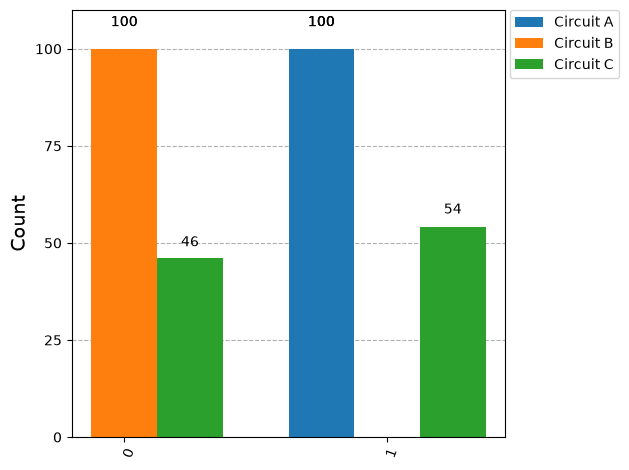

In [12]:
from qiskit.visualization import plot_histogram

plot_histogram([counts_a, counts_b, counts_c],
               legend=["Circuit A", "Circuit B", "Circuit C"])